In [29]:
import geass
from rdkit.Chem.Draw import rdMolDraw2D
import networkx as nx
import time
from urllib import parse
from rdkit import Chem
import re
from rdkit.Chem import rdChemReactions as Reactions
import ipycytoscape
import pickle
allChars = '0123456789abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ'
print('Networkx version :', nx.__version__)

Networkx version : 2.8.4


In [30]:
# Load the BUL (Biological unit library) or Natural products library

# BUL path: ../common-graph-delivery/data/BUL_names.pkl
with open('../recap-delivery/data/BUL_names.pkl', 'rb') as f:
    BULnames = pickle.load(f)

In [48]:
BULnames

{('C00001',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bc20>,
 ('C00002',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bbd0>,
 ('C00003',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bc70>,
 ('C00004',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bcc0>,
 ('C00005',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bd10>,
 ('C00006',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bd60>,
 ('C00007',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bdb0>,
 ('C00008',): <rdkit.Chem.rdchem.Mol at 0x7f140c01be00>,
 ('C00009',): <rdkit.Chem.rdchem.Mol at 0x7f140c01be50>,
 ('C00010',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bea0>,
 ('C00011',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bef0>,
 ('C00013',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bf40>,
 ('C00014',): <rdkit.Chem.rdchem.Mol at 0x7f140c01bf90>,
 ('C00015',): <rdkit.Chem.rdchem.Mol at 0x7f140c616040>,
 ('C00016',): <rdkit.Chem.rdchem.Mol at 0x7f140c616090>,
 ('C00018',): <rdkit.Chem.rdchem.Mol at 0x7f140c6160e0>,
 ('C00019',): <rdkit.Chem.rdchem.Mol at 0x7f140c616130>,
 ('C00020',): <rdkit.Chem.rdche

In [31]:
with open('../metabolic-disassembler-delivery/to_metadisassembler_v3/original_molecules.pkl', 'rb') as f:
    mols = pickle.load(f)

# Remove the modifications from the NP database

In [32]:
# The modifications in the NP database are not needed.

print('Size before revoming: ', len(BULnames))
BULnames_copy = {k:v for k, v in BULnames.items()}
for names, mol in BULnames.items():
    if len(names) == 1:
        if 'mod' in names[0]:
            del BULnames_copy[names]
            
BULnames = {k:v for k, v in BULnames_copy.items()}       
print('Size after revoming: ', len(BULnames))

Size before revoming:  20035
Size after revoming:  18409


# Create the Reactants

In [33]:
# These are the definitions that will be applied to fragment molecules:

# They include the originally defined reaction rules in RECAP and
# the modified version with the openning ring capability. 

# They DO NOT keep the dummy atoms.
 
reactionDefs = (
  "[#7;+0;D2,D3:1]!@C(!@=O)!@[#7;+0;D2,D3:2]>>[#7:1].[#7:2]", # urea + bicarbonato CHECK
  "[#7;+0;D2,D3:1]C(!@=O)[#7;+0;D2,D3:2]>>([#7:1].[#7:2])", # urea ring

  "[C;!$(C([#7])[#7]):1](=!@[O:2])!@[#7;+0;!D1:3]>>O[C:1]=[O:2].[#7:3]",  # amide not cyclic
  "[C;!$(C([#7])[#7]):1](=[O:2])[#7;+0;!D1:3]>>(O[C:1]=[O:2].[#7:3])", # amide macrocycles

  "[*:4][C:1](=!@[O:2])!@-[O;+0:3][*:5]>>[*:4][C:1](O)=[O:2].[O:3][*:5]", # ester !!!!!!!!!!!!
  #"[*:4][C:1](=!@[O:2])[O;+0:3]>>([*:4][C:1](O)=[O:2].[O:3])", # ester ring

  "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-!@[*:1])-!@[*:2]>>[*:1].[*:2]", # amines + amoniaco(?) CHECK
  "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-[*:1])-[*:2]>>([*:1].[*:2])", # amines ring
  #"[N;!D1](!@[*:1])!@[*:2]>>[*][*:1].[*:2][*]", # amines

  # again: what about aromatics?
  "[#7;R;D3;+0:1]-!@[*:2]>>[#7:1].[*:2][O]", # cyclic amines CHECK
  #"[#7;R;D3;+0:1]-[*:2]>>([#7:1].[*:2][O])", # cyclic amines ring # Seems too general?

  "[#6:1]-!@[O;+0]-!@[#6:2]>>[#6:1][O].[O][#6:2]", # ether CHECK
  "[#6:1]-[O;+0;!r6;!r5]-[#6:2]>>([#6:1][O].[O][#6:2])", # ether ring

  "[C:1]=!@[C:2]>>[C:1].[C:2]", # olefin
  #"[C:1]=[C:2]>>([C:1][*].[*][C:2])", # olefin ring

  "[n;+0:1]-!@[C:2]>>[n:1].[C:2]", # aromatic nitrogen - aliphatic carbon
  #"[n;+0:1]-[C:2]>>([n:1][*].[C:2][*])", # aromatic nitrogen - aliphatic carbon ring

  "[O:3]=[C:4]-@[N;+0:1]-!@[C:2]>>[O:3]=[C:4]-[N:1].[C:2]", # lactam nitrogen - aliphatic carbon
  #"[O:3]=[C:4]-@[N;+0:1]-[C:2]>>([O:3]=[C:4]-[N:1][*].[C:2][*])", # lactam nitrogen - aliphatic carbon ring

  "[c:1]-!@[c:2]>>[c:1].[c:2]", # aromatic carbon - aromatic carbon
  "[c:1]-[c:2]>>([c:1].[c:2])", # aromatic carbon - aromatic carbon ring

  "[n;+0:1]-!@[c:2]>>[n:1].[c:2]", # aromatic nitrogen - aromatic carbon *NOTE* this is not part of the standard recap set.
  "[n;+0:1]-[c:2]>>([n:1].[c:2])", # aromatic nitrogen - aromatic carbon ring *NOTE* this is not part of the standard recap set.

  "[#7;+0;D2,D3:1]-!@[S:2](=[O:3])=[O:4]>>[#7:1].[S:2](=[O:3])=[O:4]", # sulphonamide
  #"[#7;+0;D2,D3:1]-[S:2](=[O:3])=[O:4]>>([#7:1][*].[*][S:2](=[O:3])=[O:4])", # sulphonamide ring
  )

names = ['urea', 'ureaR', 'amide', 'amideR', 'ester', 'amines', 'aminesR', 'cyclicAmines',
        'ether', 'etherR', 'olefin', 'arNalC', 'laNalC', 'arCarC', 'arCarCR', 'arNarC',
        'arNarCR', 'sulphonamide']
reactions = dict(zip(names, reactionDefs))
reactionsMol2 = {k: Reactions.ReactionFromSmarts(v) for k, v in reactions.items()}
reactants = {k:v.GetReactants()[0] for k, v in reactionsMol2.items()}
for i, (k, v) in enumerate(reactants.items()):
    Chem.GetSymmSSSR(v)
    reactants[k] = v

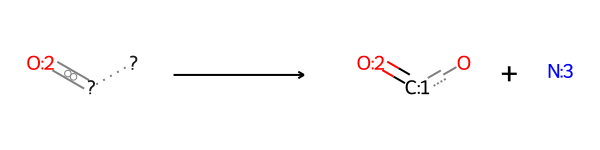

In [34]:
reactionsMol2['amide']

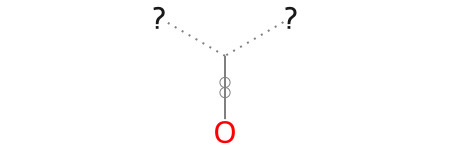

In [35]:
reactants['urea']

# Create the Bonds 

In [36]:
# Define the bonds that will be broken in each reaction

bondsMols = {
    'urea': [Chem.MolFromSmarts('[#7;+0;D2,D3:1]!@C'), Chem.MolFromSmarts('C!@[#7;+0;D2,D3:2]')],
    'ureaR': [Chem.MolFromSmarts('[#7;+0;D2,D3:1]C'), Chem.MolFromSmarts('C[#7;+0;D2,D3:2]')],
    'amide': [Chem.MolFromSmarts('[C;!$(C([#7])[#7]):1]!@[#7;+0;!D1:3]')],
    'amideR': [Chem.MolFromSmarts('[C;!$(C([#7])[#7]):1][#7;+0;!D1:3]')],
    'ether': [Chem.MolFromSmarts('[O;+0]-!@[#6:2]')],
    'etherR': [Chem.MolFromSmarts('[O;+0;!r6;!r5]-[#6:2]')],
    'ester': [Chem.MolFromSmarts('[C:1]!@-[O;+0:3]')],
    #esterR': [Chem.MolFromSmarts('[C:1][O;+0:3]')],
    'amines': [Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-!@[*:1]'), Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-!@[*:2]')],
    'aminesR': [Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-[*:1]'), Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-[*:2]')],
    'cyclicAmines': [Chem.MolFromSmarts('[#7;R;D3;+0:1]-!@[*:2]')],
    #'cyclicAminesR': [Chem.MolFromSmarts('[#7;R;D3;+0:1]-[*:2]')],
    'olefin': [Chem.MolFromSmarts('[C:1]=!@[C:2]')],
    'arNalC': [Chem.MolFromSmarts('[c:1]-!@[c:2]')],
    'laNalC': [Chem.MolFromSmarts('[N;+0:1]-!@[C:2]')],
    'arCarC': [Chem.MolFromSmarts('[c:1]-!@[c:2]')],
    'arCarCR': [Chem.MolFromSmarts('[c:1]-[c:2]')],
    'arNarC': [Chem.MolFromSmarts('[n;+0:1]-!@[c:2]')],
    'arNarCR': [Chem.MolFromSmarts('[n;+0:1]-[c:2]')],
    'sulphonamide': [Chem.MolFromSmarts('[#7;+0;D2,D3:1]-!@[S:2]')]
    
}


for k, v in bondsMols.items():
    lst = []
    for molecule in v:
        Chem.GetSymmSSSR(molecule)
        lst.append(molecule)
    bondsMols[k] = lst
    
brokenBondsDefs = {k: [molecule.GetBonds()[0] for molecule in v] for k, v in bondsMols.items()}

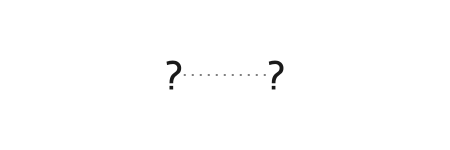

In [37]:
bondsMols['amide'][0]

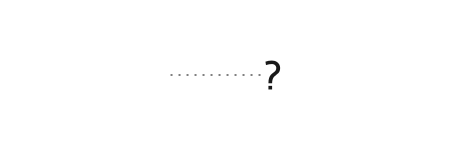

In [38]:
bondsMols['urea'][1]

# Create the atom mapping rules

In [39]:
# Atom mapping rules according to the neighbor of the dummy atom. 
# allChars is employed when any atom is replaced.
# '' wil be replaced by hidrogens so that the valences match

aux = {ch:'O' for ch in allChars}
aux.update({'N': ''})
fillingAtoms = { 'ureaR':{'N':'', 'C':'O'},
                'urea':{'N':'', 'C':'O'},
                'amide': {'N': '', 'C': 'O'},
                'amideR': {'N': '', 'C': 'O'},
                'ester': {'O': '', 'C': 'O'},
                #'esterR': {'O': '', 'C': 'O'},
                'ether': {'O': '', 'C': 'O', 'c':'O'},
                'etherR': {'O': '', 'C': 'O', 'c':'O', 'o':''},
               'amines': {ch:'' for ch in allChars},
               'aminesR': {ch:'' for ch in allChars},
               'cyclicAmines':aux,
               #'cyclicAminesR': {ch:'O' for ch in allChars}.update({'N': ''}),
               'olefin': {'C': ''},
               'arNalC': {'N': '', 'C': '', 'n': '', 'c': ''},
               'laNalC': {'N': '', 'C': '', 'n': '', 'c': ''},
               'arCarC': {'C': '', 'c': ''},
               'arCarCR': {'C': '', 'c': ''},
                'arNarC': {'C': '', 'c': '', 'N': '', 'n': ''},
               'arNarCR': {'C': '', 'c': '', 'N': '', 'n': ''},
               'sulphonamide': {'N': '', 'S': ''}}

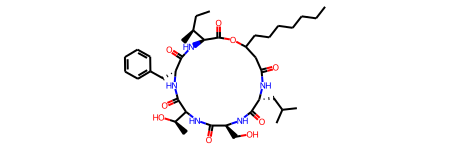

In [40]:
# Sample a random molecule from a list

import random
idx = random.randint(0, 1959)
mols[idx]

In [41]:
# ---------------------------------------  STEP 0 ----------------------------------------------
# Initialize the GEASS fragmentator.
# The verbose argument controls the number of messages shown.
# The ester reaction is still giving an error

# Explicar la automatizacion de los inputs.

fragmentator = geass.Geass(mols[idx], brokenBondsDefs, reactants, fillingAtoms, BULnames, verbose=0)

In [47]:
type(fragmentator)

geass.Geass

In [42]:
# ---------------------------------------  STEP 1 ----------------------------------------------

# This method detects the bonds in the molecule to be broken

fragmentator.get_bonds_to_break()

In [43]:
# You can explore the detected bonds and their type.

fragmentator.breakable_mol_bonds

{11: 'amideR',
 16: 'amideR',
 21: 'amideR',
 26: 'amideR',
 31: 'amideR',
 7: 'etherR'}

In [44]:
# ---------------------------------------  STEP 2 ----------------------------------------------

# This function will create a graph (Networkx like) containing the fragments of the molecule

fragmentator.create_fragmentation_graph()

In [45]:
# Here we explore the graph:

print(type(fragmentator.graph))
print('Number of nodes: ', len(fragmentator.graph.nodes))
print('Number of edges: ', len(fragmentator.graph.edges))
print('Node Attributes ', fragmentator.graph.nodes[0].keys())

<class 'networkx.classes.graph.Graph'>
Number of nodes:  6
Number of edges:  6
Node Attributes  dict_keys(['SMILES', 'img', 'isNP'])


In [46]:
# ---------------------------------------  STEP 3 ----------------------------------------------

# Plot the graph. Nodes whose attribute 'isNP' is Yes will be plotted in green. Otherwise, in red.

fragmentator.plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

# Success analysis

In [19]:
start_from = 0
results = {}
for i, mol in enumerate(mols[start_from:]):
    j = i + start_from
    print(f'Progress [{j}/{len(mols)-1}]', end='\r')
    fragmentator = geass.Geass(mol, brokenBondsDefs, reactants, fillingAtoms, BULnames, verbose=0)
    fragmentator.get_bonds_to_break()
    fragmentator.create_fragmentation_graph()
    NPs = nx.get_node_attributes(fragmentator.graph, 'isNP')
    results[j] = {'NP': len([node for node, isNP in NPs.items() if isNP == 'Yes']),
                 'NotNP': len([node for node, isNP in NPs.items() if isNP == 'No'])}

No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.

No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.

No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.


RDKit WARNING: [21:03:05] WARNING: not removing hydrogen atom without neighbors
[21:03:05] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [21:03:05] WARNING: not removing hydrogen atom without neighbors
[21:03:05] WARNING: not removing hydrogen atom without neighbors


No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.

In [20]:
success = len([k for k, v in results.items() if v['NotNP'] == 0])
print(f'Success rate: {success/len(results)}' )

Success rate: 0.19693877551020408


In [21]:
rates = {k:v['NP']/(v['NP'] + v['NotNP']) for k, v in results.items() if v['NP'] + v['NotNP'] != 0}

In [23]:
import seaborn as sns

<AxesSubplot:ylabel='Count'>

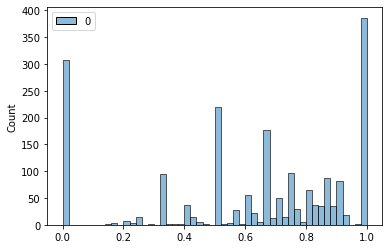

In [24]:
sns.histplot(rates.values(), bins = 50)

In [25]:
import numpy as np
np.mean(list(rates.values()))

0.6187537643921998